# 06_07 — Covariance Analysis

Three analyses of the IPCA model's feature and factor structure:
1. **Characteristic correlation matrix** — which characteristics cluster together
2. **Factor covariance matrix** — how latent factors co-move
3. **Implied beta covariance** — `Γ @ Cov(F) @ Γᵀ`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

out_dir = Path("outputs")

CHAR_COLS = [
    "bond_age", "coupon", "face_value", "duration", "spread", "rating",
    "mom_6m", "mom_6m_industry", "mom_6m_x_rating", "bond_skewness",
    "mom_6m_log_spread", "bond_volatility", "value_at_risk",
    "book_to_price", "debt_to_ebitda", "mom_6m_equity", "earnings_to_price",
    "equity_market_cap", "equity_volatility", "firm_total_debt",
    "book_leverage", "market_leverage", "turnover_volatility",
    "operating_leverage", "profitability", "profitability_change",
    "distance_to_default", "spread_to_d2d",
]

panel = pd.read_parquet(out_dir / "ipca_panel_input.parquet").reset_index()
print(f"Panel: {panel.shape[0]:,} bond-months, {len(CHAR_COLS)} characteristics")

Panel: 83,934 bond-months, 28 characteristics


## 1. Characteristic Correlation Matrix

Characteristics are rank-standardised to [-0.5, 0.5] each month, so the covariance matrix is equivalent to a correlation matrix. The clustermap reorders rows/columns by hierarchical clustering to reveal natural groupings.

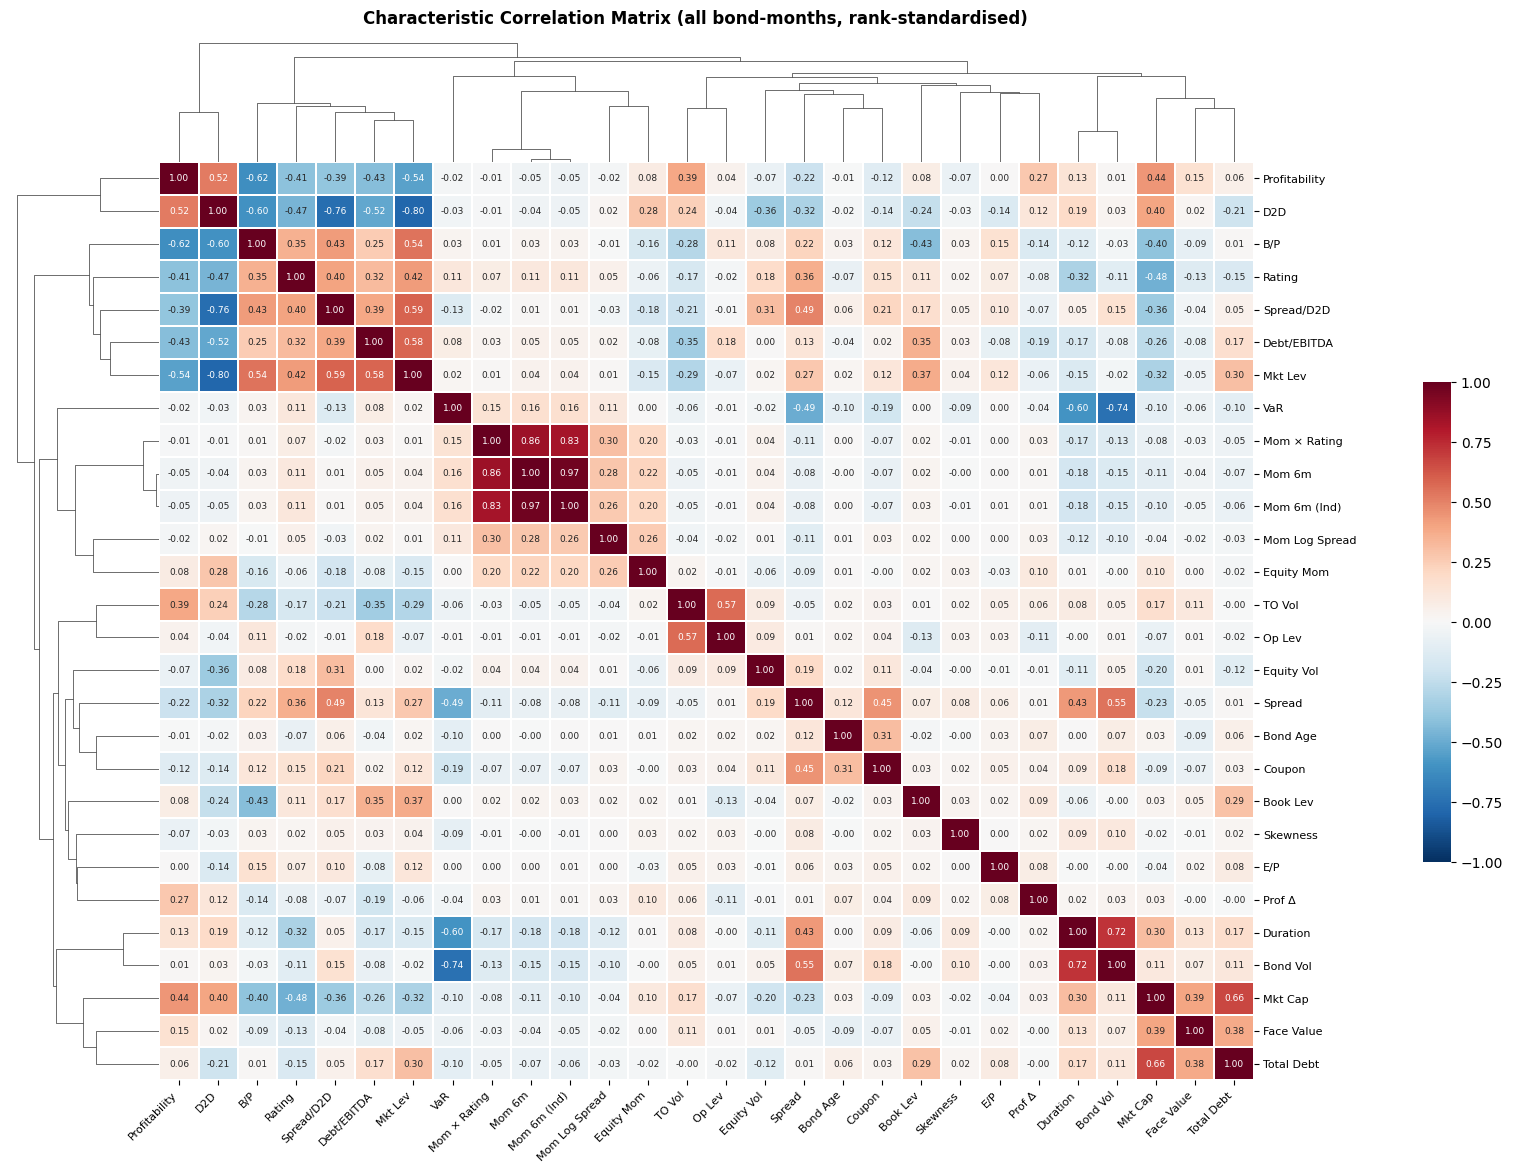

Saved → outputs/ipca_insample/fig5_char_correlation.png


In [2]:
corr = panel[CHAR_COLS].corr()

# Prettier labels for the heatmap
labels = {
    "bond_age": "Bond Age", "coupon": "Coupon", "face_value": "Face Value",
    "duration": "Duration", "spread": "Spread", "rating": "Rating",
    "mom_6m": "Mom 6m", "mom_6m_industry": "Mom 6m (Ind)",
    "mom_6m_x_rating": "Mom × Rating", "bond_skewness": "Skewness",
    "mom_6m_log_spread": "Mom Log Spread", "bond_volatility": "Bond Vol",
    "value_at_risk": "VaR", "book_to_price": "B/P",
    "debt_to_ebitda": "Debt/EBITDA", "mom_6m_equity": "Equity Mom",
    "earnings_to_price": "E/P", "equity_market_cap": "Mkt Cap",
    "equity_volatility": "Equity Vol", "firm_total_debt": "Total Debt",
    "book_leverage": "Book Lev", "market_leverage": "Mkt Lev",
    "turnover_volatility": "TO Vol", "operating_leverage": "Op Lev",
    "profitability": "Profitability", "profitability_change": "Prof Δ",
    "distance_to_default": "D2D", "spread_to_d2d": "Spread/D2D",
}
corr_labeled = corr.rename(index=labels, columns=labels)

cg = sns.clustermap(
    corr_labeled,
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    annot_kws={"size": 6.5},
    linewidths=0.3,
    figsize=(14, 12),
    dendrogram_ratio=0.12,
    cbar_pos=(1.02, 0.3, 0.02, 0.4),
)
cg.ax_heatmap.set_xticklabels(
    cg.ax_heatmap.get_xticklabels(), rotation=45, ha="right", fontsize=8
)
cg.ax_heatmap.set_yticklabels(
    cg.ax_heatmap.get_yticklabels(), rotation=0, fontsize=8
)
cg.figure.suptitle(
    "Characteristic Correlation Matrix (all bond-months, rank-standardised)",
    y=1.01, fontsize=12, fontweight="bold"
)

cg.savefig(out_dir / "ipca_insample" / "fig5_char_correlation.png",
           dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig5_char_correlation.png")

In [3]:
# Top correlated pairs (|r| > 0.4, excluding diagonal)
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .rename("r")
        .reset_index()
        .rename(columns={"level_0": "char_a", "level_1": "char_b"})
)
pairs["abs_r"] = pairs["r"].abs()
top = pairs[pairs["abs_r"] > 0.4].sort_values("abs_r", ascending=False)
print(f"Pairs with |r| > 0.4: {len(top)}\n")
print(top.to_string(index=False))

Pairs with |r| > 0.4: 32

             char_a              char_b         r    abs_r
             mom_6m     mom_6m_industry  0.973066 0.973066
             mom_6m     mom_6m_x_rating  0.858617 0.858617
    mom_6m_industry     mom_6m_x_rating  0.830508 0.830508
    market_leverage distance_to_default -0.796018 0.796018
distance_to_default       spread_to_d2d -0.762193 0.762193
    bond_volatility       value_at_risk -0.742299 0.742299
           duration     bond_volatility  0.721785 0.721785
  equity_market_cap     firm_total_debt  0.664969 0.664969
      book_to_price       profitability -0.623347 0.623347
      book_to_price distance_to_default -0.604466 0.604466
           duration       value_at_risk -0.597472 0.597472
    market_leverage       spread_to_d2d  0.588151 0.588151
     debt_to_ebitda     market_leverage  0.583917 0.583917
turnover_volatility  operating_leverage  0.569152 0.569152
             spread     bond_volatility  0.546803 0.546803
    market_leverage       prof

## 2. Factor Covariance Matrix

IPCA factors are **not** constrained to be orthogonal (unlike PCA), so off-diagonal entries can be non-zero. The diagonal shows each factor's variance; off-diagonals reveal co-movement between latent factors.

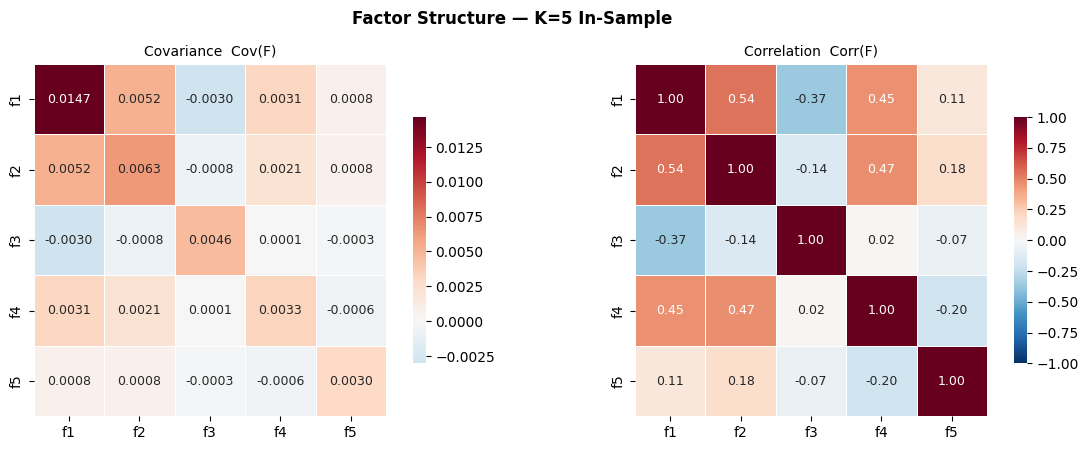

Saved → outputs/ipca_insample/fig6_factor_covariance.png

Factor annualised volatilities:
  f1: 41.95%
  f2: 27.56%
  f3: 23.51%
  f4: 19.80%
  f5: 18.82%


In [4]:
F = pd.read_parquet(out_dir / "ipca_insample" / "factors_K5.parquet")
cov_F = F.cov()
corr_F = F.corr()

factor_labels = [f"f{k+1}" for k in range(5)]
cov_F.index = corr_F.index = factor_labels
cov_F.columns = corr_F.columns = factor_labels

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("Factor Structure — K=5 In-Sample", fontsize=12, fontweight="bold")

sns.heatmap(
    cov_F, ax=axes[0], cmap="RdBu_r", center=0,
    annot=True, fmt=".4f", annot_kws={"size": 9},
    linewidths=0.5, square=True, cbar_kws={"shrink": 0.7},
)
axes[0].set_title("Covariance  Cov(F)", fontsize=10)

sns.heatmap(
    corr_F, ax=axes[1], cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 9},
    linewidths=0.5, square=True, cbar_kws={"shrink": 0.7},
)
axes[1].set_title("Correlation  Corr(F)", fontsize=10)

plt.tight_layout()
plt.savefig(out_dir / "ipca_insample" / "fig6_factor_covariance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig6_factor_covariance.png")

print("\nFactor annualised volatilities:")
for i, col in enumerate(F.columns):
    print(f"  f{i+1}: {F[col].std() * np.sqrt(12) * 100:.2f}%")

## 3. Implied Beta Covariance

Each bond's beta is `β_i = Γ zᵢ`. The covariance of betas across characteristics is:

$$\text{Cov}(\beta) = \Gamma \cdot \text{Cov}(F) \cdot \Gamma^\top$$

This 28×28 matrix tells you which characteristics the model treats as similar in terms of their **implied factor exposure**. Pairs with high values load onto the same latent factors. A bar chart of row norms `||Γᵢ||₂` ranks characteristics by total factor loading magnitude.

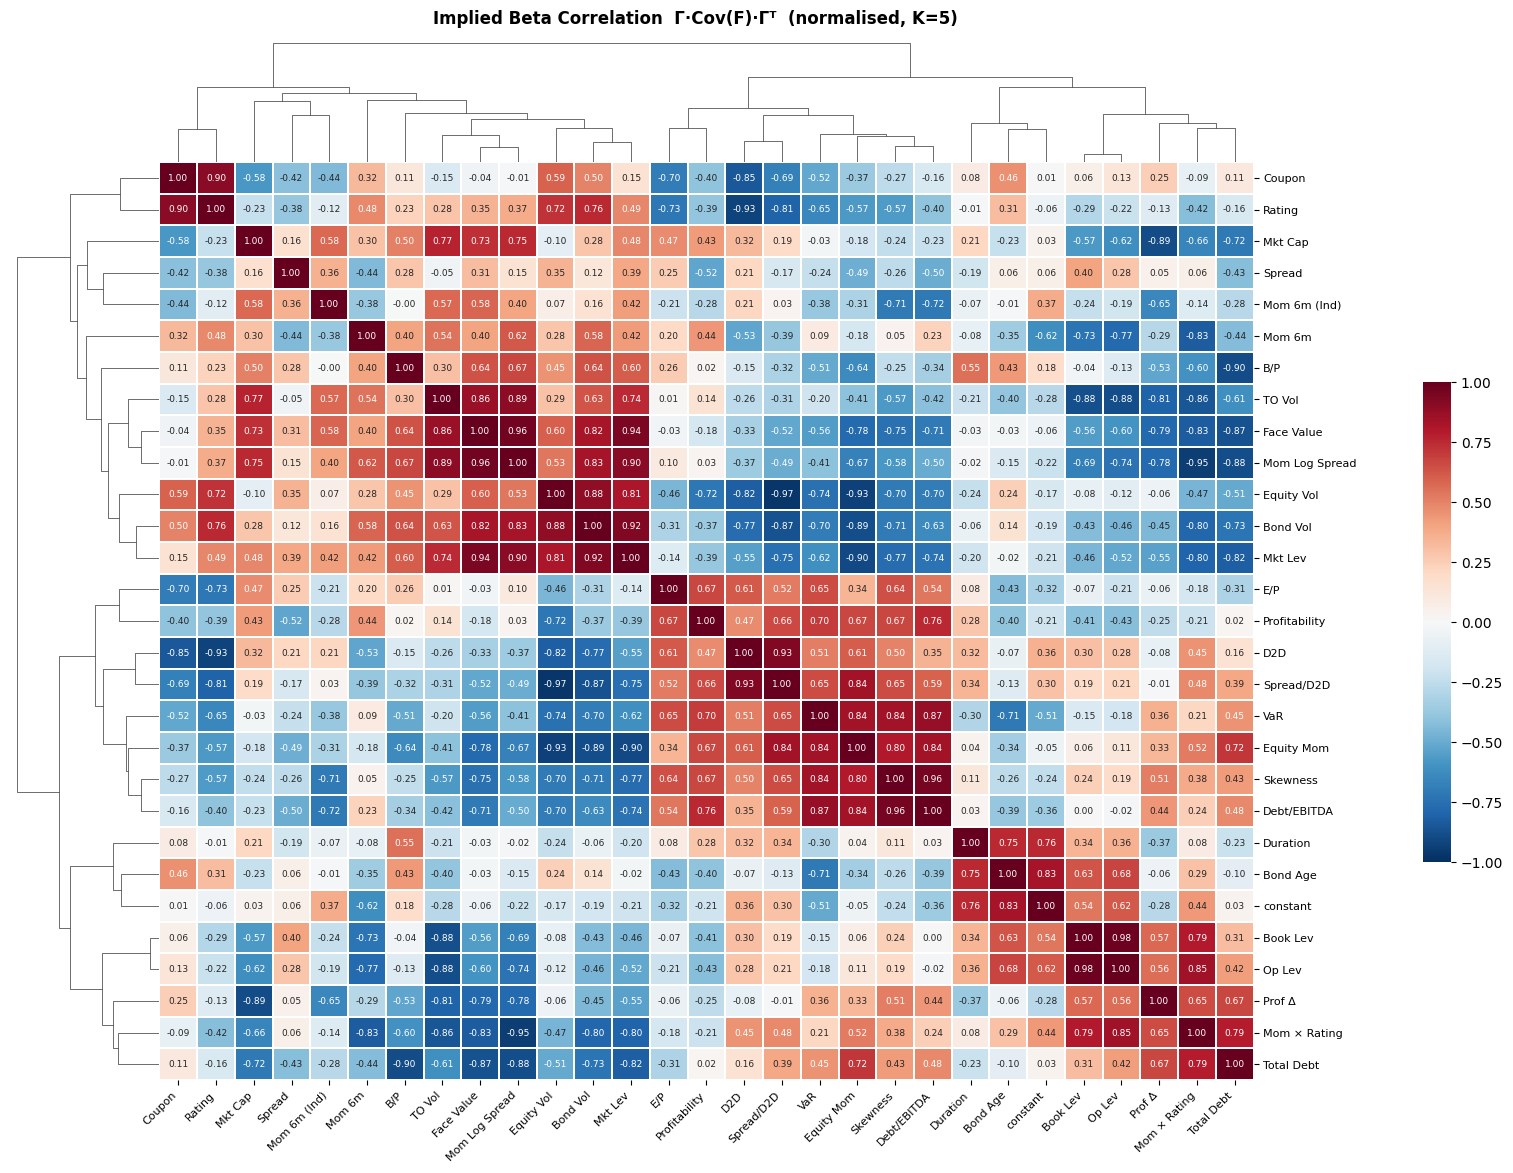

Saved → outputs/ipca_insample/fig7_beta_covariance.png


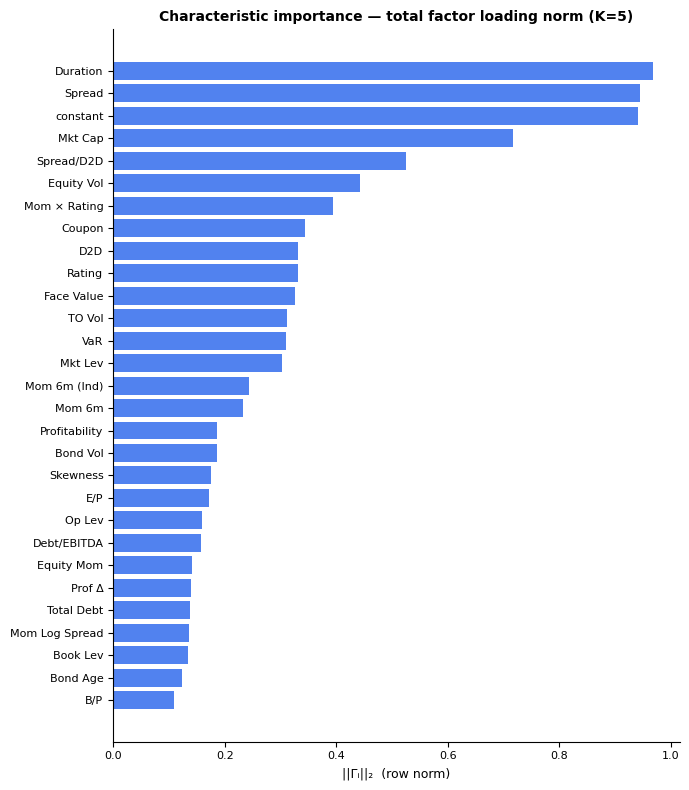

Saved → outputs/ipca_insample/fig8_char_importance.png


In [5]:
gamma = pd.read_parquet(out_dir / "ipca_insample" / "gamma_beta_K5.parquet")  # shape: L × K

cov_beta = gamma.values @ cov_F.values @ gamma.values.T
std_beta = np.sqrt(np.diag(cov_beta))
corr_beta = cov_beta / np.outer(std_beta, std_beta)
corr_beta_df = pd.DataFrame(corr_beta, index=gamma.index, columns=gamma.index)
corr_beta_df = corr_beta_df.rename(index=labels, columns=labels)

cg2 = sns.clustermap(
    corr_beta_df,
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 6.5},
    linewidths=0.3, figsize=(14, 12),
    dendrogram_ratio=0.12, cbar_pos=(1.02, 0.3, 0.02, 0.4),
)
cg2.ax_heatmap.set_xticklabels(
    cg2.ax_heatmap.get_xticklabels(), rotation=45, ha="right", fontsize=8
)
cg2.ax_heatmap.set_yticklabels(
    cg2.ax_heatmap.get_yticklabels(), rotation=0, fontsize=8
)
cg2.figure.suptitle(
    "Implied Beta Correlation  Γ·Cov(F)·Γᵀ  (normalised, K=5)",
    y=1.01, fontsize=12, fontweight="bold"
)
cg2.savefig(out_dir / "ipca_insample" / "fig7_beta_covariance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig7_beta_covariance.png")

# Characteristic importance: L2 norm of each Gamma row
importance = pd.Series(
    np.linalg.norm(gamma.values, axis=1), index=gamma.index
).sort_values(ascending=True)
readable_labels = [labels.get(c, c) for c in importance.index]

fig2, ax2 = plt.subplots(figsize=(7, 8))
ax2.barh(readable_labels, importance.values, color="#2563EB", alpha=0.8)
ax2.set_xlabel("||Γᵢ||₂  (row norm)", fontsize=9)
ax2.set_title("Characteristic importance — total factor loading norm (K=5)", fontsize=10, fontweight="bold")
ax2.spines[["top", "right"]].set_visible(False)
ax2.tick_params(labelsize=8)
plt.tight_layout()
plt.savefig(out_dir / "ipca_insample" / "fig8_char_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig8_char_importance.png")